# TP 2 — Construire un pipeline Deep Learning

## 0. Environnement

In [1]:
import re
import time
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 120)

print("Environnement prêt.")

Environnement prêt.


## 1. Nettoyage & prétraitement

### 1.1 Recharger le corpus et reconstruire la tâche du TP1

On réutilise sans modification la fonction de parsing comme dans le TP1 : elle découpe le corpus en
blocs séparés par une ligne vide, et retient les blocs dont la première ligne est un nom en
majuscules suivi de `:`.

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(URL).read().decode("utf-8")


def parser_repliques(txt: str) -> pd.DataFrame:
    # Découpe le corpus en répliques (locuteur, texte). Identique au TP1.
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)
df["n_mots"] = df["replique"].str.split().str.len()

top5 = df["locuteur"].value_counts().head(5).index
d = df[df["locuteur"].isin(top5)].query("n_mots >= 5").reset_index(drop=True)

print(f"{len(d)} répliques ,  5 locuteurs (reprise du choix du TP1)")
print(d["locuteur"].value_counts())

761 répliques — 5 locuteurs (reprise du choix du TP1)
locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64


### 1.2 Découper AVANT toute transformation

Comme au TP1, le split précède toute construction de vocabulaire ou de vectoriseur — sans
quoi le vocabulaire du réseau de neurones contiendrait des mots vus uniquement dans le test,
ce qui fausserait l'évaluation exactement de la même façon qu'un `fit_transform` sur le test
au TP1.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    d["replique"], d["locuteur"], test_size=0.2,
    stratify=d["locuteur"], random_state=RANDOM_STATE,
)

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

print(f"train : {len(X_train)}   test : {len(X_test)}")
print("classes :", list(le.classes_))

baseline_acc = y_test.value_counts(normalize=True).max()
print(f"\nbaseline (classe majoritaire) : {baseline_acc:.3f}")

train : 608   test : 153
classes : ['DUKE VINCENTIO', 'GLOUCESTER', 'MENENIUS', 'PETRUCHIO', 'ROMEO']

baseline (classe majoritaire) : 0.261


### 1.3 Nettoyage spécifique au Deep Learning : tokenisation et vocabulaire

TF‑IDF (section 2.1) tolère la ponctuation et la casse : `TfidfVectorizer` s'en charge en
interne. Un réseau à embeddings ne tolère rien de tout ça : *chaque token doit correspondre à
un indice entier dans une table fixe. Il faut donc :

1. passer en minuscules et retirer la ponctuation (sinon `"lord,"` et `"lord"` sont deux tokens
   différents) ;
2. découper sur les espaces ;
3. construire un vocabulaire seulement sur le train, en retirant les mots trop rares
   (`min_df = 2`, comme au TP1) pour limiter le nombre de paramètres d'embedding ;
4. remplacer tout mot du test absent du vocabulaire par un indice `<UNK>` (0).

In [4]:
def tokeniser(texte_brut: str) -> list[str]:
    t = texte_brut.lower()
    t = re.sub(r"[^a-z' ]", " ", t)
    return t.split()


tok_train = [tokeniser(s) for s in X_train]
tok_test = [tokeniser(s) for s in X_test]

compteur = Counter(tok for doc in tok_train for tok in doc)
vocabulaire = [mot for mot, c in compteur.items() if c >= 2]
mot2id = {mot: i + 1 for i, mot in enumerate(vocabulaire)}  # 0 réservé à <UNK>
TAILLE_VOCAB = len(vocabulaire) + 1


def encoder(doc_tokens: list[str]) -> list[int]:
    ids = [mot2id.get(t, 0) for t in doc_tokens]
    return ids if ids else [0]


seq_train = [encoder(t) for t in tok_train]
seq_test = [encoder(t) for t in tok_test]

n_unk_test = sum(tid == 0 for seq in seq_test for tid in seq)
n_tok_test = sum(len(seq) for seq in seq_test)

print(f"taille du vocabulaire (train, min_df=2) : {TAILLE_VOCAB}")
print(f"tokens <UNK> dans le test : {n_unk_test}/{n_tok_test} ({n_unk_test/n_tok_test:.1%})")

taille du vocabulaire (train, min_df=2) : 1582
tokens <UNK> dans le test : 770/4933 (15.6%)


> Le taux de mots inconnus dans le test donne une idée du coût du choix
> `min_df=2` : c'est le prix à payer pour ne pas allouer un vecteur d'embedding à des mots vus
> une seule fois, qui ne seraient jamais entraînés correctement de toute façon.

## 2. Représentation

### 2.1 Représentation classique : TF‑IDF (rappel du TP1)

On reprend telle quelle la meilleure configuration du TP1 : unigrammes + bigrammes,
`min_df=2`, `sublinear_tf=True`. Cette matrice **sparse** servira de représentation pour les
modèles ML et pour un premier modèle DL peu profond (section 3.2).

In [5]:
vectoriseur_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)
X_train_tfidf = vectoriseur_tfidf.fit_transform(X_train)
X_test_tfidf = vectoriseur_tfidf.transform(X_test)

print(f"dimension TF-IDF   : {X_train_tfidf.shape[1]:,} colonnes")
print(f"densité de la matrice train : {X_train_tfidf.nnz / (X_train_tfidf.shape[0]*X_train_tfidf.shape[1]):.2%}")

dimension TF-IDF   : 3,464 colonnes
densité de la matrice train : 0.97%


### 2.2 Représentation dense apprise : une couche d'embedding

La différence de nature entre les deux représentations est le cœur du TP :

| | TF‑IDF | Embeddings |
|---|---|---|
| Dimension par mot | 1 colonne, fixe | `D` valeurs continues, **apprises** |
| Construction | statistique (comptage pondéré) | initialisation aléatoire, ajustée par gradient |
| Relation entre mots proches | aucune (colonnes indépendantes) | mots au sens proche → vecteurs proches, *si assez de données* |
| Dimension du document | taille du vocabulaire (~1 800) | `D` (ici 50), quel que soit le vocabulaire |

Un document est représenté comme la **moyenne des embeddings de ses tokens** (pooling moyen) —
la même idée que le "bag of words" du TP1, mais sur des vecteurs denses plutôt que sur des
comptages.

In [ ]:
DIM_EMBEDDING = 50
DIM_CACHEE = 64
N_CLASSES = len(le.classes_)

W_emb = rng.normal(0, 0.1, (TAILLE_VOCAB, DIM_EMBEDDING))
W1 = rng.normal(0, (2 / (DIM_EMBEDDING + DIM_CACHEE)) ** 0.5, (DIM_EMBEDDING, DIM_CACHEE))
b1 = np.zeros(DIM_CACHEE)
W2 = rng.normal(0, (2 / (DIM_CACHEE + N_CLASSES)) ** 0.5, (DIM_CACHEE, N_CLASSES))
b2 = np.zeros(N_CLASSES)

n_params = W_emb.size + W1.size + b1.size + W2.size + b2.size
print(f"paramètres de la table d'embedding : {W_emb.size:,}")
print(f"paramètres totaux du réseau        : {n_params:,}")
print(f"exemples d'entraînement disponibles : {len(X_train)}")
print(f"ratio paramètres / exemples         : {n_params/len(X_train):.0f}")

paramètres de la table d'embedding : 79,100
paramètres totaux du réseau        : 82,689
exemples d'entraînement disponibles : 608
ratio paramètres / exemples         : 136


> **Le chiffre à faire remarquer.** Le ratio paramètres/exemples est très supérieur à 1 —
> on est très loin du régime "big data" dans lequel le deep learning excelle habituellement.
> Ce simple calcul, fait *avant* d'entraîner quoi que ce soit, devrait alerter l'étudiant sur
> un risque de surapprentissage. C'est le prolongement direct du point de contrôle n°5.

## 3. Comparaison entre modèles ML et DL

### 3.1 Modèles ML classiques (rappel du TP1, sur ce split)

Trois modèles linéaires/probabilistes sur TF‑IDF, comme au TP1.

In [7]:
modeles_ml = {
    "LogisticRegression": LogisticRegression(max_iter=2000, C=5, class_weight="balanced", random_state=RANDOM_STATE),
    "LinearSVC": LinearSVC(C=1, class_weight="balanced", random_state=RANDOM_STATE),
    "MultinomialNB": MultinomialNB(),
}

resultats = {}
for nom, modele in modeles_ml.items():
    modele.fit(X_train_tfidf, y_train)
    pred = modele.predict(X_test_tfidf)
    resultats[nom] = {
        "famille": "ML",
        "accuracy": accuracy_score(y_test, pred),
        "F1 macro": f1_score(y_test, pred, average="macro"),
    }

pd.DataFrame(resultats).T.round(3)

,famille,accuracy,F1 macro
LogisticRegression,ML,0.666667,0.668665
LinearSVC,ML,0.647059,0.648625
MultinomialNB,ML,0.562092,0.53507


### 3.2 DL peu profond : un perceptron multicouche sur TF‑IDF

Première façon de faire du deep learning sans réapprendre de représentation : empiler une
couche cachée au-dessus de la représentation TF‑IDF déjà construite. Le réseau n'a que
la frontière de décision à apprendre, pas la représentation elle-même. Il devrait donc être
moins exposé au surapprentissage que le modèle de la section 3.3.

In [8]:
mlp_tfidf = MLPClassifier(
    hidden_layer_sizes=(64,), activation="relu", alpha=1e-3,
    max_iter=300, random_state=RANDOM_STATE,
)
mlp_tfidf.fit(X_train_tfidf, y_train_enc)
pred_mlp = mlp_tfidf.predict(X_test_tfidf)
pred_mlp_train = mlp_tfidf.predict(X_train_tfidf)

resultats["MLP sur TF-IDF"] = {
    "famille": "DL",
    "accuracy": accuracy_score(y_test_enc, pred_mlp),
    "F1 macro": f1_score(y_test_enc, pred_mlp, average="macro"),
}
print(f"accuracy train : {accuracy_score(y_train_enc, pred_mlp_train):.3f}")
print(f"accuracy test  : {accuracy_score(y_test_enc, pred_mlp):.3f}")

accuracy train : 1.000
accuracy test  : 0.654


### 3.3 DL "pur" : embeddings appris + réseau feedforward, codés à la main

Ici, on n'utilise aucune bibliothèque de deep learning : l'objectif est de
voir ce qu'il y a derrière `model.fit()` : propagation avant, rétropropagation du gradient,
et maj des poids avec Adam, le tout en `numpy`.

Architecture : `embedding (moyenne) → couche cachée ReLU (64) → softmax (5 classes)`.

In [ ]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def propagation_avant(sequences):
    embeddings_moyens = np.zeros((len(sequences), DIM_EMBEDDING))
    for i, ids in enumerate(sequences):
        embeddings_moyens[i] = W_emb[ids].mean(axis=0)
    z1 = embeddings_moyens @ W1 + b1
    a1 = np.maximum(0, z1)          # ReLU
    z2 = a1 @ W2 + b2
    probs = softmax(z2)
    return embeddings_moyens, z1, a1, probs


parametres = [W_emb, W1, b1, W2, b2]
m_adam = [np.zeros_like(p) for p in parametres]
v_adam = [np.zeros_like(p) for p in parametres]
BETA1, BETA2, EPS_ADAM, LR = 0.9, 0.999, 1e-8, 0.01

N_EPOCHS, TAILLE_BATCH = 60, 32
n_train = len(seq_train)
pas = 0
historique_loss = []

for epoque in range(N_EPOCHS):
    ordre = rng.permutation(n_train)
    perte_epoque = 0.0
    for debut in range(0, n_train, TAILLE_BATCH):
        indices = ordre[debut:debut + TAILLE_BATCH]
        seqs_batch = [seq_train[i] for i in indices]
        y_batch = y_train_enc[indices]
        taille_batch = len(indices)

        embs, z1, a1, probs = propagation_avant(seqs_batch)
        log_probs = -np.log(np.clip(probs[np.arange(taille_batch), y_batch], 1e-12, 1))
        perte_epoque += log_probs.sum()

        y_onehot = np.zeros((taille_batch, N_CLASSES))
        y_onehot[np.arange(taille_batch), y_batch] = 1
        dz2 = (probs - y_onehot) / taille_batch
        dW2, db2 = a1.T @ dz2, dz2.sum(axis=0)
        da1 = dz2 @ W2.T
        dz1 = da1 * (z1 > 0)
        dW1, db1 = embs.T @ dz1, dz1.sum(axis=0)
        d_embs = dz1 @ W1.T

        dW_emb = np.zeros_like(W_emb)
        for i, ids in enumerate(seqs_batch):
            dW_emb[ids] += d_embs[i] / len(ids)

        pas += 1
        for p, g, m_, v_ in zip(parametres, [dW_emb, dW1, db1, dW2, db2], m_adam, v_adam):
            m_[:] = BETA1 * m_ + (1 - BETA1) * g
            v_[:] = BETA2 * v_ + (1 - BETA2) * (g ** 2)
            m_corrige = m_ / (1 - BETA1 ** pas)
            v_corrige = v_ / (1 - BETA2 ** pas)
            p -= LR * m_corrige / (np.sqrt(v_corrige) + EPS_ADAM)

    historique_loss.append(perte_epoque / n_train)
    if epoque % 10 == 0 or epoque == N_EPOCHS - 1:
        print(f"époque {epoque:3d}  perte train = {historique_loss[-1]:.4f}")

époque   0  perte train = 1.5796
époque  10  perte train = 0.0010
époque  20  perte train = 0.0003
époque  30  perte train = 0.0001
époque  40  perte train = 0.0001
époque  50  perte train = 0.0001
époque  59  perte train = 0.0000


In [10]:
_, _, _, probs_train_dl = propagation_avant(seq_train)
_, _, _, probs_test_dl = propagation_avant(seq_test)
pred_train_dl = probs_train_dl.argmax(axis=1)
pred_test_dl = probs_test_dl.argmax(axis=1)

acc_train_dl = accuracy_score(y_train_enc, pred_train_dl)
acc_test_dl = accuracy_score(y_test_enc, pred_test_dl)

resultats["Embeddings appris (from scratch)"] = {
    "famille": "DL",
    "accuracy": acc_test_dl,
    "F1 macro": f1_score(y_test_enc, pred_test_dl, average="macro"),
}

print(f"accuracy train : {acc_train_dl:.3f}")
print(f"accuracy test  : {acc_test_dl:.3f}")
print(f"écart train-test : {acc_train_dl - acc_test_dl:.3f}  <-- surapprentissage")

accuracy train : 1.000
accuracy test  : 0.634
écart train-test : 0.366  <-- surapprentissage


### 3.4 Tableau comparatif

On rassemble ici les cinq modèles — trois ML, deux DL — évalués sur le **même** split test.

In [11]:
tableau_final = pd.DataFrame(resultats).T
tableau_final["accuracy"] = tableau_final["accuracy"].astype(float).round(3)
tableau_final["F1 macro"] = tableau_final["F1 macro"].astype(float).round(3)
tableau_final = tableau_final.sort_values("F1 macro", ascending=False)
tableau_final

,famille,accuracy,F1 macro
LogisticRegression,ML,0.667,0.669
MLP sur TF-IDF,DL,0.654,0.655
LinearSVC,ML,0.647,0.649
Embeddings appris (from scratch),DL,0.634,0.629
MultinomialNB,ML,0.562,0.535


> La régression logistique sur TF‑IDF reste le meilleur modèle.
> Le MLP sur TF‑IDF (DL peu profond, représentation figée) fait presque jeu égal avec les
> modèles ML. Le réseau à embeddings appris (DL "pur") est le moins bon des cinq, alors
> qu'il est le plus complexe — c'est précisément parce qu'il doit apprendre sa représentation
> en plus de la frontière de décision, avec 10 fois moins de signal par paramètre que les
> autres modèles.

## 4. Évaluation

**Métrique retenue : le F1 macro**, pour la même raison qu'au TP1 — les 5 classes ne sont
pas équilibrées (126 à 196 exemples), et l'accuracy seule surpondérerait GLOUCESTER.

### 4.1 Matrices de confusion : meilleur ML contre DL pur

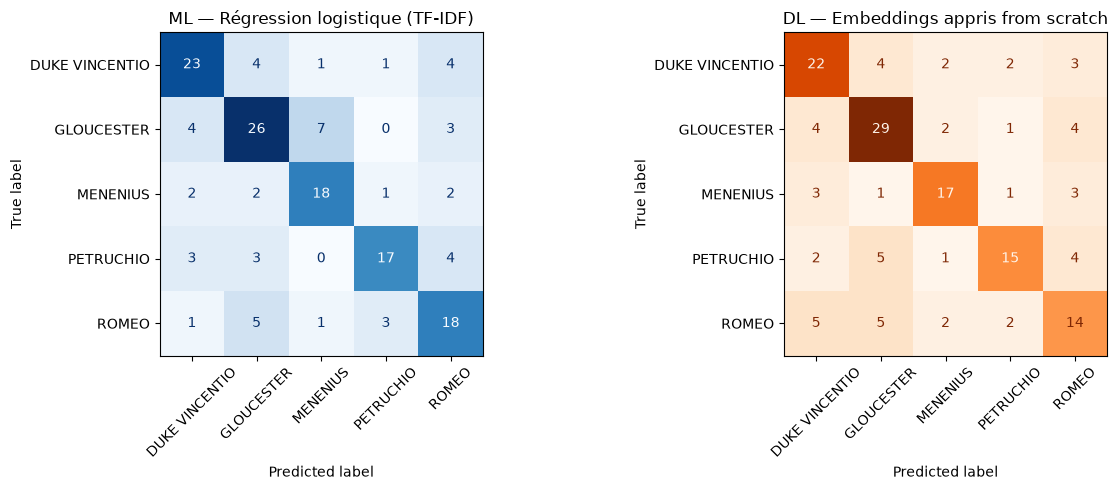

In [12]:
meilleur_ml = modeles_ml["LogisticRegression"]
pred_ml = meilleur_ml.predict(X_test_tfidf)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_ml, ax=axes[0], xticks_rotation=45, colorbar=False, cmap="Blues"
)
axes[0].set_title("ML — Régression logistique (TF-IDF)")

ConfusionMatrixDisplay.from_predictions(
    le.inverse_transform(y_test_enc), le.inverse_transform(pred_test_dl),
    ax=axes[1], xticks_rotation=45, colorbar=False, cmap="Oranges"
)
axes[1].set_title("DL — Embeddings appris from scratch")

plt.tight_layout()
plt.show()

### 4.2 Visualiser le surapprentissage

La courbe de perte du réseau à embeddings (section 3.3) s'effondre en une quinzaine d'époques
— bien plus vite qu'on ne pourrait l'espérer d'un vrai apprentissage sur un problème à 5
classes. Ce n'est pas un signe de qualité : c'est le signe que le modèle **mémorise** le
train.

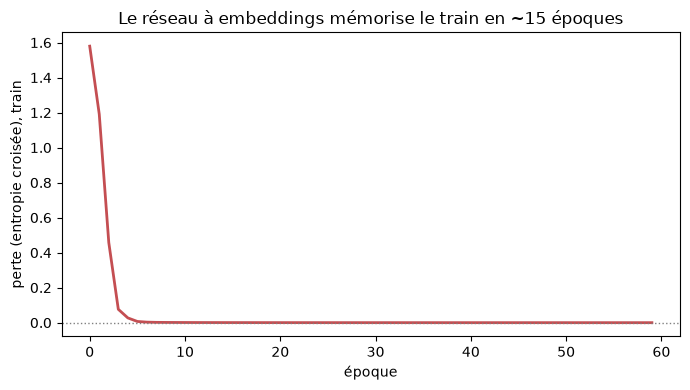

accuracy train : 100.0%   |   accuracy test : 63.4%


In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(historique_loss, color="#C44E52", linewidth=2)
ax.axhline(0, color="grey", ls=":", linewidth=1)
ax.set_xlabel("époque")
ax.set_ylabel("perte (entropie croisée), train")
ax.set_title("Le réseau à embeddings mémorise le train en ~15 époques")
plt.tight_layout()
plt.show()

print(f"accuracy train : {acc_train_dl:.1%}   |   accuracy test : {acc_test_dl:.1%}")

>Une perte train qui tend vers 0 alors que la perte/accuracy test
> stagne est **la** signature du surapprentissage — le TP1 demandait de lire une matrice de
> confusion jusqu'au bout ; ce TP2 demande de lire une courbe d'apprentissage jusqu'au bout.
> Un étudiant qui s'arrête à "la perte baisse, c'est bien" n'a pas compris le signal.

### 4.3 Ce que le réseau a appris : voisins dans l'espace d'embedding

Une façon qualitative d'inspecter la représentation apprise : chercher, pour quelques mots,
leurs plus proches voisins par similarité cosinus dans `W_emb`.

In [14]:
def plus_proches_voisins(mot, k=5):
    if mot not in mot2id:
        return f"'{mot}' hors vocabulaire"
    v = W_emb[mot2id[mot]]
    normes = W_emb / (np.linalg.norm(W_emb, axis=1, keepdims=True) + 1e-9)
    sims = normes @ (v / (np.linalg.norm(v) + 1e-9))
    meilleurs = np.argsort(-sims)[1:k + 1]
    id2mot = {i: m for m, i in mot2id.items()}
    return [(id2mot.get(i, "<UNK>"), round(float(sims[i]), 2)) for i in meilleurs]


for mot in ["lord", "death", "love", "king"]:
    print(f"{mot:>8} -> {plus_proches_voisins(mot)}")

    lord -> [('brother', 0.9), ('cousin', 0.87), ('grace', 0.87), ('avoid', 0.86), ('rutland', 0.85)]
   death -> [('rest', 0.81), ('pardon', 0.77), ('hold', 0.75), ('already', 0.75), ('die', 0.75)]
    love -> [('course', 0.78), ('stretch', 0.76), ('despised', 0.76), ('removed', 0.76), ('farewell', 0.75)]
    king -> [('clarence', 0.94), ('sovereignty', 0.94), ('edward', 0.94), ('castle', 0.93), ('hatred', 0.93)]


---

## Synthèse

Les messages qui ressortent :

1. Le deep learning n'est pas un supplément de performance automatique. C'est un choix de
   modèle avec ses propres conditions de validité, ici, le volume de données.
2. Compter les paramètres avant d'entraîner (section 2.2) aurait permis de prédire le
   problème sans lancer une seule époque.
3. Une courbe de perte qui s'effondre trop vite est un signal d'alerte, pas une victoire.
   Toujours la lire en regard de la métrique de test.
4. Séparer représentation et modélisation aide à diagnostiquer. Le MLP sur TF-IDF (DL,
   représentation figée) est resté compétitif ; seul le modèle qui réapprend sa représentation
   s'est effondré. La cause du problème est localisée.
